In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [9]:

DATA_PATH = "../data/processed/restaurant_final_cleaned2.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


Dataset loaded successfully!
Shape: (156329, 27)

Columns:
['Risk', 'Inspection Date', 'Inspection Type', 'Results', 'Violations', 'Location', 'Restaurant_ID', 'Inspection_Sequence', 'Days_Since_Previous_Inspection', 'Inspection_Year', 'Inspection_Month', 'Inspection_Quarter', 'Inspection_DayOfWeek', 'Violations_Text_Available', 'Violation_Count', 'Latitude', 'Longitude', 'Geo_Grid_ID', 'Geo_Region_ID', 'Administrative_Count', 'Average_Violation_Score', 'Compliant_Positive_Count', 'Hazard_Count', 'Mapped_Violation_Count', 'Number_of_Violations', 'Unclear_Count', 'Unmatched_Violation_Count']


In [10]:

df["Inspection Date"] = pd.to_datetime(
    df["Inspection Date"],
    errors="coerce"
)

print("Invalid or missing inspection dates:",
      df["Inspection Date"].isna().sum())

print("Earliest inspection:",
      df["Inspection Date"].min())

print("Latest inspection:",
      df["Inspection Date"].max())


Invalid or missing inspection dates: 0
Earliest inspection: 2010-01-04 00:00:00
Latest inspection: 2026-10-02 00:00:00


In [11]:

seasonal_columns = [
    "Inspection_Year",
    "Inspection_Month",
    "Inspection_Quarter",
    "Inspection_DayOfWeek",
    "Results"
]

missing_columns = [
    col for col in seasonal_columns
    if col not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required seasonal analysis columns are available.")

    print("\nDataset shape:", df.shape)

    print("\nYear range:")
    print(df["Inspection_Year"].min(), "to", df["Inspection_Year"].max())

    print("\nAvailable inspection outcomes:")
    print(df["Results"].value_counts())


All required seasonal analysis columns are available.

Dataset shape: (156329, 27)

Year range:
2010 to 2026

Available inspection outcomes:
Results
0    118663
1     37666
Name: count, dtype: int64


In [13]:

print("Dataset shape:", df.shape)

print("\nResults column:")
print(df["Results"].value_counts(dropna=False))

print("\nFailure_Target column:")
if "Failure_Target" in df.columns:
    print(df["Failure_Target"].value_counts(dropna=False))
else:
    print("Failure_Target has not been created yet.")

print("\nTarget cross-check:")
if "Failure_Target" in df.columns:
    print(pd.crosstab(df["Results"], df["Failure_Target"]))


Dataset shape: (156329, 27)

Results column:
Results
0    118663
1     37666
Name: count, dtype: int64

Failure_Target column:
Failure_Target has not been created yet.

Target cross-check:


In [14]:

yearly_summary = (
    df.groupby("Inspection_Year")
    .agg(
        Total_Inspections=("Results", "count"),
        Failed_Inspections=("Results", "sum"),
        Failure_Rate=("Results", "mean")
    )
    .reset_index()
)

yearly_summary["Failure_Rate_Pct"] = (
    yearly_summary["Failure_Rate"] * 100
).round(2)

print(
    yearly_summary[
        [
            "Inspection_Year",
            "Total_Inspections",
            "Failed_Inspections",
            "Failure_Rate_Pct"
        ]
    ].to_string(index=False)
)


 Inspection_Year  Total_Inspections  Failed_Inspections  Failure_Rate_Pct
            2010               7999                2116             26.45
            2011               8463                2136             25.24
            2012               8529                1889             22.15
            2013              10126                2002             19.77
            2014              11732                2292             19.54
            2015              10887                2363             21.70
            2016              12368                2902             23.46
            2017              11256                2797             24.85
            2018               8877                2049             23.08
            2019              10054                2350             23.37
            2020               6872                1742             25.35
            2021               7634                2000             26.20
            2022               8173   

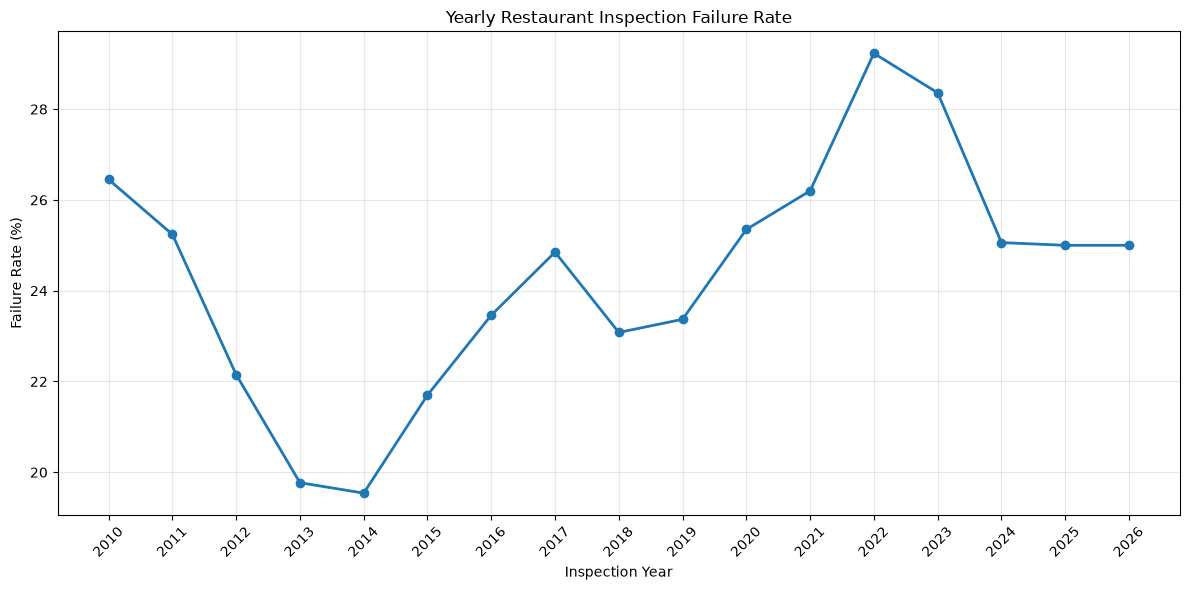

In [15]:

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_summary["Inspection_Year"],
    yearly_summary["Failure_Rate_Pct"],
    marker="o",
    linewidth=2
)

plt.title("Yearly Restaurant Inspection Failure Rate")
plt.xlabel("Inspection Year")
plt.ylabel("Failure Rate (%)")
plt.xticks(yearly_summary["Inspection_Year"], rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:

monthly_summary = (
    df.groupby("Inspection_Month")
    .agg(
        Total_Inspections=("Results", "count"),
        Failed_Inspections=("Results", "sum"),
        Failure_Rate=("Results", "mean")
    )
    .reset_index()
)

monthly_summary["Failure_Rate_Pct"] = (
    monthly_summary["Failure_Rate"] * 100
).round(2)

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

monthly_summary["Month_Name"] = (
    monthly_summary["Inspection_Month"].map(month_names)
)

print(
    monthly_summary[
        [
            "Month_Name",
            "Total_Inspections",
            "Failed_Inspections",
            "Failure_Rate_Pct"
        ]
    ].to_string(index=False)
)


Month_Name  Total_Inspections  Failed_Inspections  Failure_Rate_Pct
   January              13127                3042             23.17
  February              11994                2778             23.16
     March              14347                3252             22.67
     April              13859                3218             23.22
       May              14005                3279             23.41
      June              14779                3699             25.03
      July              12623                3195             25.31
    August              14447                3782             26.18
 September              12819                3355             26.17
   October              13150                3329             25.32
  November              11166                2602             23.30
  December              10013                2135             21.32


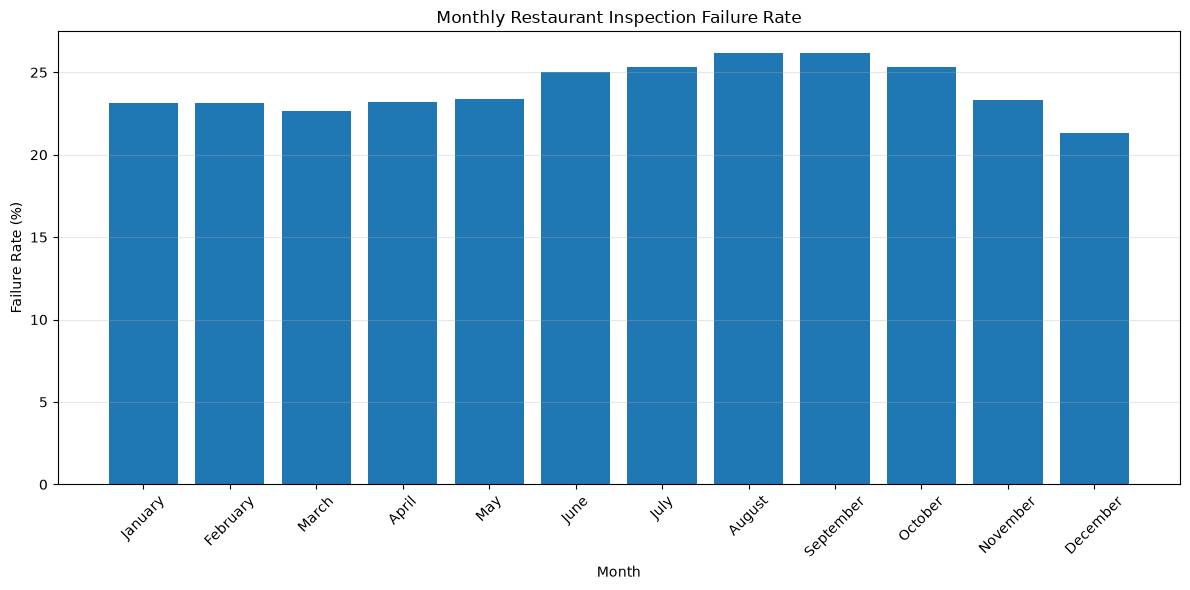

In [17]:

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_summary["Month_Name"],
    monthly_summary["Failure_Rate_Pct"]
)

plt.title("Monthly Restaurant Inspection Failure Rate")
plt.xlabel("Month")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

quarterly_summary = (
    df.groupby("Inspection_Quarter")
    .agg(
        Total_Inspections=("Results", "count"),
        Failed_Inspections=("Results", "sum"),
        Failure_Rate=("Results", "mean")
    )
    .reset_index()
)

quarterly_summary["Failure_Rate_Pct"] = (
    quarterly_summary["Failure_Rate"] * 100
).round(2)

quarterly_summary["Quarter"] = (
    "Q" + quarterly_summary["Inspection_Quarter"].astype(str)
)

print(
    quarterly_summary[
        [
            "Quarter",
            "Total_Inspections",
            "Failed_Inspections",
            "Failure_Rate_Pct"
        ]
    ].to_string(index=False)
)


Quarter  Total_Inspections  Failed_Inspections  Failure_Rate_Pct
     Q1              39468                9072             22.99
     Q2              42643               10196             23.91
     Q3              39889               10332             25.90
     Q4              34329                8066             23.50


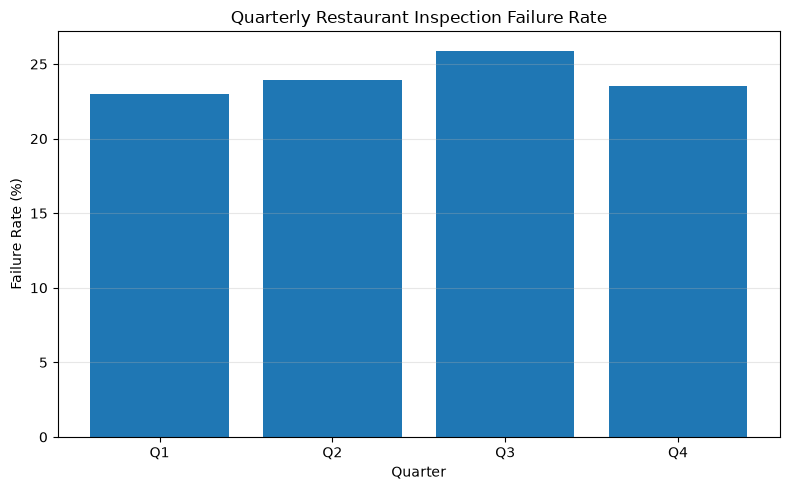

In [19]:

plt.figure(figsize=(8, 5))

plt.bar(
    quarterly_summary["Quarter"],
    quarterly_summary["Failure_Rate_Pct"]
)

plt.title("Quarterly Restaurant Inspection Failure Rate")
plt.xlabel("Quarter")
plt.ylabel("Failure Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_summary = (
    df.groupby("Inspection_DayOfWeek")
    .agg(
        Total_Inspections=("Results", "count"),
        Failed_Inspections=("Results", "sum"),
        Failure_Rate=("Results", "mean")
    )
    .reindex(weekday_order)
    .reset_index()
)

weekday_summary["Failure_Rate_Pct"] = (
    weekday_summary["Failure_Rate"] * 100
).round(2)

print(
    weekday_summary[
        [
            "Inspection_DayOfWeek",
            "Total_Inspections",
            "Failed_Inspections",
            "Failure_Rate_Pct"
        ]
    ].to_string(index=False)
)


Inspection_DayOfWeek  Total_Inspections  Failed_Inspections  Failure_Rate_Pct
              Monday              26561                6606             24.87
             Tuesday              34771                8533             24.54
           Wednesday              29835                7077             23.72
            Thursday              35071                8485             24.19
              Friday              30068                6958             23.14
            Saturday                 20                   7             35.00
              Sunday                  3                   0              0.00


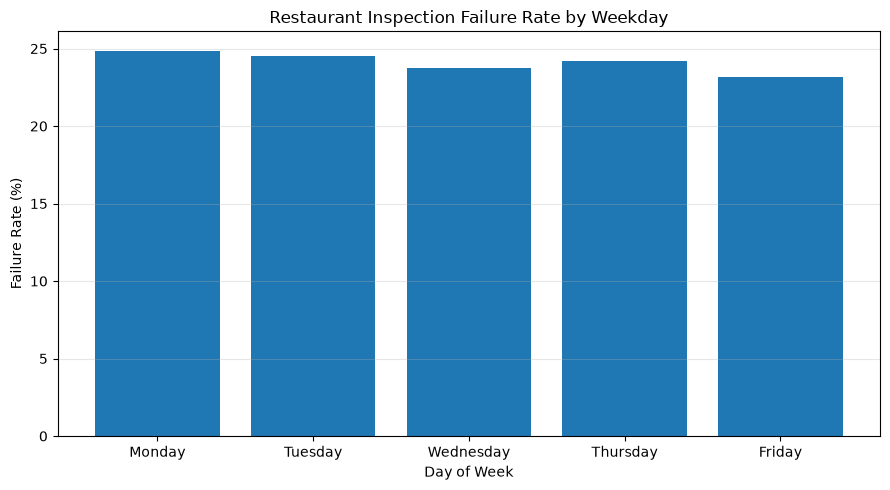

In [21]:

weekday_only = weekday_summary[
    weekday_summary["Inspection_DayOfWeek"].isin(
        ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
    )
].copy()

plt.figure(figsize=(9, 5))

plt.bar(
    weekday_only["Inspection_DayOfWeek"],
    weekday_only["Failure_Rate_Pct"]
)

plt.title("Restaurant Inspection Failure Rate by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Failure Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:

year_quarter_summary = (
    df.groupby(["Inspection_Year", "Inspection_Quarter"])
    .agg(
        Total_Inspections=("Results", "count"),
        Failed_Inspections=("Results", "sum"),
        Failure_Rate=("Results", "mean")
    )
    .reset_index()
)

year_quarter_summary["Failure_Rate_Pct"] = (
    year_quarter_summary["Failure_Rate"] * 100
).round(2)

print(
    year_quarter_summary[
        [
            "Inspection_Year",
            "Inspection_Quarter",
            "Total_Inspections",
            "Failed_Inspections",
            "Failure_Rate_Pct"
        ]
    ].to_string(index=False)
)


 Inspection_Year  Inspection_Quarter  Total_Inspections  Failed_Inspections  Failure_Rate_Pct
            2010                   1               1821                 453             24.88
            2010                   2               2004                 515             25.70
            2010                   3               2300                 643             27.96
            2010                   4               1874                 505             26.95
            2011                   1               2250                 464             20.62
            2011                   2               2196                 563             25.64
            2011                   3               2096                 612             29.20
            2011                   4               1921                 497             25.87
            2012                   1               2146                 449             20.92
            2012                   2               2181     

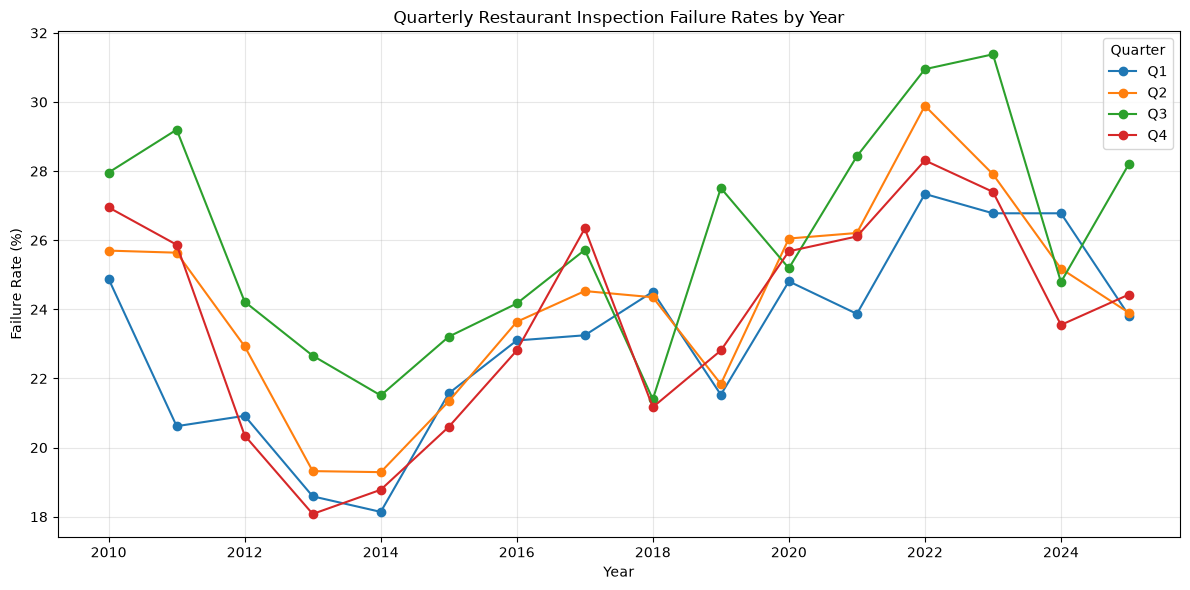

In [23]:

quarterly_pivot = year_quarter_summary.pivot(
    index="Inspection_Year",
    columns="Inspection_Quarter",
    values="Failure_Rate_Pct"
)

# Exclude 2026 because Q4 has only 20 inspections
quarterly_pivot = quarterly_pivot.loc[quarterly_pivot.index < 2026]

plt.figure(figsize=(12, 6))

for quarter in [1, 2, 3, 4]:
    plt.plot(
        quarterly_pivot.index,
        quarterly_pivot[quarter],
        marker="o",
        label=f"Q{quarter}"
    )

plt.title("Quarterly Restaurant Inspection Failure Rates by Year")
plt.xlabel("Year")
plt.ylabel("Failure Rate (%)")
plt.legend(title="Quarter")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:

from pathlib import Path

OUTPUT_DIR = Path("../reports/seasonal_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

yearly_summary.to_csv(
    OUTPUT_DIR / "yearly_failure_summary.csv",
    index=False
)

monthly_summary.to_csv(
    OUTPUT_DIR / "monthly_failure_summary.csv",
    index=False
)

quarterly_summary.to_csv(
    OUTPUT_DIR / "quarterly_failure_summary.csv",
    index=False
)

weekday_summary.to_csv(
    OUTPUT_DIR / "weekday_failure_summary.csv",
    index=False
)

year_quarter_summary.to_csv(
    OUTPUT_DIR / "year_quarter_failure_summary.csv",
    index=False
)

print("Seasonal summary tables saved to:", OUTPUT_DIR)


Seasonal summary tables saved to: ..\reports\seasonal_analysis
